In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler,MinMaxScaler
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score

In [2]:
import os
path = "/content/Wednesday-workingHours.pcap_ISCX.csv"
print(os.path.getsize(path) / 1e6, "MB")

225.166395 MB


In [3]:
with open(path, "rb") as f:
    print(sum(1 for _ in f))

692704


In [4]:
import pandas as pd

df_raw = pd.read_csv(path)
print(df_raw.shape)

(692703, 79)


In [5]:
df_raw[' Label'].value_counts()

,count
Label,
BENIGN,440031
DoS Hulk,231073
DoS GoldenEye,10293
DoS slowloris,5796
DoS Slowhttptest,5499
Heartbleed,11


missing values handling

In [6]:
df_cleaned = df_raw.dropna()  # Drop rows with NaN values
df_cleaned = df_cleaned[~df_cleaned.isin([np.inf, -np.inf]).any(axis=1)] # Drop rows with out of range values

In [7]:
data = df_cleaned.iloc[:,:-1]   # data contains clean attributes
labels = df_cleaned.iloc[:,-1]  # labels contain the corresponding labels in categorical format ('BENIGN','DoS slowloris',... )

In [8]:




# identifying zero-variance features
zero_variance_features = data.var() == 0
zero_variance_index = zero_variance_features[zero_variance_features].index
print("Features with zero variance:\n", zero_variance_index)

Features with zero variance:
 Index([' Bwd PSH Flags', ' Fwd URG Flags', ' Bwd URG Flags', ' CWE Flag Count',
       'Fwd Avg Bytes/Bulk', ' Fwd Avg Packets/Bulk', ' Fwd Avg Bulk Rate',
       ' Bwd Avg Bytes/Bulk', ' Bwd Avg Packets/Bulk', 'Bwd Avg Bulk Rate'],
      dtype='object')


In [9]:
# Droping the specified columns (i.e., those with zero variance)
data_dropped_zero_var = data.drop(columns= zero_variance_index)

In [10]:
# Finding identical columns
columns = data_dropped_zero_var.columns
identical_columns = []

for col1 in data_dropped_zero_var.columns:
    for col2 in data_dropped_zero_var.columns:
        if col1 != col2 and data_dropped_zero_var[col1].equals(data_dropped_zero_var[col2]):
            identical_columns.append((col1, col2))

print("Identical columns:", identical_columns)

Identical columns: [(' Total Fwd Packets', 'Subflow Fwd Packets'), (' Total Backward Packets', ' Subflow Bwd Packets'), ('Total Length of Fwd Packets', ' Subflow Fwd Bytes'), (' Fwd Packet Length Mean', ' Avg Fwd Segment Size'), ('Fwd PSH Flags', ' SYN Flag Count'), (' Fwd Header Length', ' Fwd Header Length.1'), (' SYN Flag Count', 'Fwd PSH Flags'), (' Avg Fwd Segment Size', ' Fwd Packet Length Mean'), (' Fwd Header Length.1', ' Fwd Header Length'), ('Subflow Fwd Packets', ' Total Fwd Packets'), (' Subflow Fwd Bytes', 'Total Length of Fwd Packets'), (' Subflow Bwd Packets', ' Total Backward Packets')]


In [11]:
# Use a set to filter out tuples considering (X, Y) and (Y, X) as the same
unique_pairs = set()

# Add each tuple to the set in a sorted order (to avoid duplicates with reversed order)
for pair in identical_columns:
    unique_pairs.add(tuple(sorted(pair)))

# Convert back to list to maintain the same structure as original input
unique_tuples_list = list(unique_pairs)

# Output the result
print(unique_tuples_list)

[(' Subflow Bwd Packets', ' Total Backward Packets'), (' Subflow Fwd Bytes', 'Total Length of Fwd Packets'), (' SYN Flag Count', 'Fwd PSH Flags'), (' Fwd Header Length', ' Fwd Header Length.1'), (' Total Fwd Packets', 'Subflow Fwd Packets'), (' Avg Fwd Segment Size', ' Fwd Packet Length Mean')]


In [12]:
 #Extract the columns to drop (second item of each tuple)
columns_to_drop = [pair[1] for pair in unique_tuples_list]

In [13]:
# Drop the duplicate columns from the DataFrame
data_var_ident_dropped = data_dropped_zero_var.drop(columns=columns_to_drop)

In [14]:
scaler = StandardScaler()
scaled_data = scaler.fit_transform(data_var_ident_dropped)  # it converts pandas dataframe into a numpy array


In [15]:
cov_matrix = np.cov(scaled_data, rowvar=False)

covariance

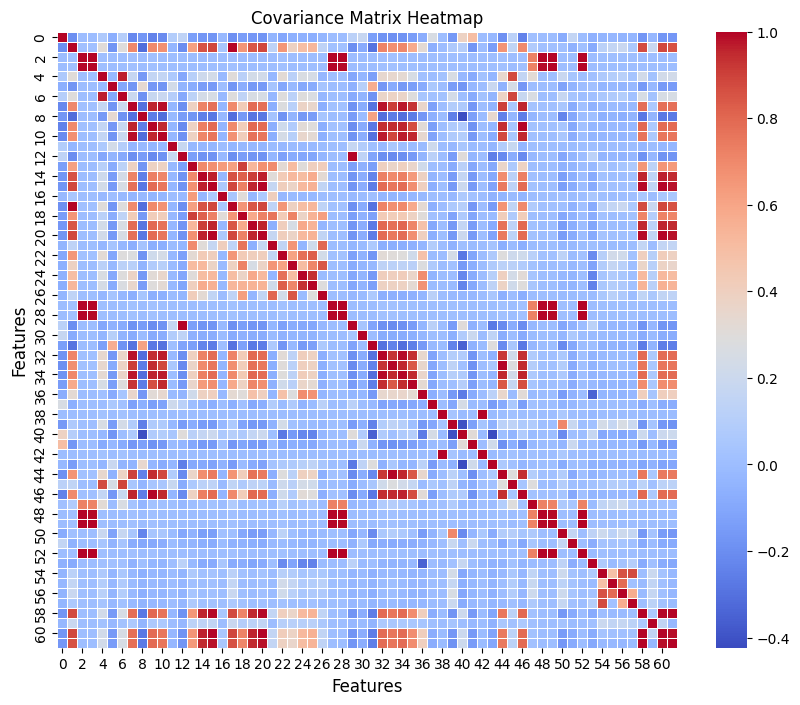

In [16]:
plt.figure(figsize=(10, 8))

# Create the heatmap using seaborn
sns.heatmap(cov_matrix, annot=False, cmap="coolwarm", fmt='.2f', linewidths=0.5)

# Add labels and title
plt.title('Covariance Matrix Heatmap', fontsize=12)
plt.xlabel('Features', fontsize=12)
plt.ylabel('Features', fontsize=12)

# Show the plot
plt.show()

In [17]:
# Convert categorical labels to numerical values
labels_numeric = labels.apply(lambda x: 0 if x == 'BENIGN' else 1)

In [18]:
# Concatenate labels with cleaned data
cleaned_data_labels = pd.concat([data_var_ident_dropped, labels_numeric.rename('Label')], axis=1)

In [19]:
X = cleaned_data_labels.iloc[:, :-1]  # features: all columns except the last one
y = cleaned_data_labels.iloc[:, -1]   # targets : last column

In [20]:
# Split the data into training and validation sets.
from sklearn.model_selection import train_test_split
X_train, X_valid, y_train, y_valid = train_test_split(X, y, test_size=0.3, random_state=42)

In [21]:
y_valid.shape

(207422,)

In [22]:
##### scratch implementation
def sigmoid(z): return 1 / (1 + np.exp(-z))

def logloss(y, p):
    p = np.clip(p, 1e-15, 1 - 1e-15)
    return -np.mean(y*np.log(p) + (1-y)*np.log(1-p))

In [23]:
class Tree:
    def __init__(self, max_depth, reg_lambda, gamma, min_child_weight):
        self.max_depth, self.lam, self.gamma, self.mcw = max_depth, reg_lambda, gamma, min_child_weight
        self.feature, self.thr, self.left, self.right, self.value = [], [], [], [], []
        self.stats = []                      # (feature, gain, cover) for every split made

    def _new_node(self):
        for l, v in ((self.feature, -1), (self.thr, 0.0), (self.left, -1),
                     (self.right, -1), (self.value, 0.0)):
            l.append(v)
        return len(self.feature) - 1

    def fit(self, Xb, g, h, edges, eta):
        self.edges, self.eta = edges, eta
        self._grow(self._new_node(), np.arange(len(g)), Xb, g, h, 0)
        for name in ("feature", "thr", "left", "right", "value"):
            setattr(self, name, np.array(getattr(self, name)))
        return self

    def _grow(self, node, idx, Xb, g, h, depth):
        G, H = g[idx].sum(), h[idx].sum()
        self.value[node] = -G / (H + self.lam) * self.eta      # leaf weight
        if depth == self.max_depth:
            return
        Xn, gn, hn = Xb[idx], g[idx], h[idx]
        best_gain, best_f, best_b = 0.0, -1, -1
        for f in range(Xb.shape[1]):
            gh = np.bincount(Xn[:, f], weights=gn, minlength=256)   # sum of g per bin
            hh = np.bincount(Xn[:, f], weights=hn, minlength=256)   # sum of h per bin
            GL, HL = np.cumsum(gh), np.cumsum(hh)
            GR, HR = G - GL, H - HL
            gain = 0.5 * (GL**2/(HL+self.lam) + GR**2/(HR+self.lam) - G**2/(H+self.lam)) - self.gamma
            gain[(HL < self.mcw) | (HR < self.mcw)] = -np.inf
            b = gain.argmax()
            if gain[b] > best_gain:
                best_gain, best_f, best_b = gain[b], f, b
        if best_f == -1:                                       # no useful split -> leaf
            return
        self.feature[node] = best_f
        self.thr[node] = self.edges[best_f][best_b]            # threshold in raw feature units
        self.stats.append((best_f, best_gain, H))
        go_left = Xn[:, best_f] <= best_b
        l, r = self._new_node(), self._new_node()
        self.left[node], self.right[node] = l, r
        self._grow(l, idx[go_left], Xb, g, h, depth + 1)
        self._grow(r, idx[~go_left], Xb, g, h, depth + 1)

    def predict(self, X):
        node = np.zeros(len(X), dtype=int)
        rows = np.arange(len(X))
        for _ in range(self.max_depth):
            f = self.feature[node]
            internal = f >= 0
            go_left = X[rows, np.where(internal, f, 0)] <= self.thr[node]
            node = np.where(internal, np.where(go_left, self.left[node], self.right[node]), node)
        return self.value[node]

In [24]:
class SimpleXGBoost:
    def __init__(self, max_depth=4, eta=0.1, reg_lambda=1.0, gamma=0.0,
                 min_child_weight=1.0, n_bins=256):
        self.max_depth, self.eta, self.reg_lambda = max_depth, eta, reg_lambda
        self.gamma, self.mcw, self.n_bins = gamma, min_child_weight, n_bins

    def fit(self, X, y, X_valid, y_valid, num_rounds=50, early_stopping_rounds=10):
        self.columns = list(X.columns)
        Xv, yv = X.values.astype(float), y.values.astype(float)
        Xval, yval = X_valid.values.astype(float), y_valid.values.astype(float)

        # bin every feature once (quantile bins)
        q = np.linspace(0, 1, self.n_bins + 1)[1:-1]
        edges = [np.unique(np.quantile(Xv[:, j], q)) for j in range(Xv.shape[1])]
        Xb = np.column_stack([np.searchsorted(edges[j], Xv[:, j], side="left")
                              for j in range(Xv.shape[1])]).astype(np.uint8)

        p0 = yv.mean()
        self.base = np.log(p0 / (1 - p0))                      # starting prediction (log-odds)
        F, Fval = np.full(len(yv), self.base), np.full(len(yval), self.base)
        self.trees, self.history = [], {"train": [], "eval": []}
        best, best_round = np.inf, 0

        for r in range(num_rounds):
            p = sigmoid(F)
            g, h = p - yv, p * (1 - p)                         # gradient, hessian of logloss
            t = Tree(self.max_depth, self.reg_lambda, self.gamma, self.mcw).fit(Xb, g, h, edges, self.eta)
            self.trees.append(t)
            F += t.predict(Xv)
            Fval += t.predict(Xval)

            tr, ev = logloss(yv, sigmoid(F)), logloss(yval, sigmoid(Fval))
            self.history["train"].append(tr); self.history["eval"].append(ev)
            print(f"[{r}] train-logloss:{tr:.5f} eval-logloss:{ev:.5f}")

            if ev < best: best, best_round = ev, r
            elif r - best_round >= early_stopping_rounds:
                print("early stopping at round", r); break
        self.trees = self.trees[:best_round + 1]               # keep best iteration
        return self

    def predict_proba(self, X):
        Xv = X.values.astype(float)
        F = np.full(len(Xv), self.base)
        for t in self.trees: F += t.predict(Xv)
        return sigmoid(F)

    def importance(self):
        rows = [(self.columns[f], gain, cover) for t in self.trees for f, gain, cover in t.stats]
        df = pd.DataFrame(rows, columns=["feat", "gain", "cover"])
        out = df.groupby("feat").agg(gain=("gain", "mean"),     # average gain per split
                                     cover=("cover", "mean"),   # average hessian at split
                                     weight=("gain", "size"))   # number of splits
        return out.reindex(self.columns).fillna(0)

In [25]:
model = SimpleXGBoost(max_depth=4, eta=0.1)
model.fit(X_train, y_train, X_valid, y_valid, num_rounds=50, early_stopping_rounds=10)

[0] train-logloss:0.56634 eval-logloss:0.56649
[1] train-logloss:0.49530 eval-logloss:0.49546
[2] train-logloss:0.43711 eval-logloss:0.43727
[3] train-logloss:0.38852 eval-logloss:0.38869
[4] train-logloss:0.34740 eval-logloss:0.34758
[5] train-logloss:0.30961 eval-logloss:0.30979
[6] train-logloss:0.27711 eval-logloss:0.27729
[7] train-logloss:0.24897 eval-logloss:0.24914
[8] train-logloss:0.22444 eval-logloss:0.22460
[9] train-logloss:0.20297 eval-logloss:0.20314
[10] train-logloss:0.18411 eval-logloss:0.18428
[11] train-logloss:0.16748 eval-logloss:0.16762
[12] train-logloss:0.15278 eval-logloss:0.15292
[13] train-logloss:0.13955 eval-logloss:0.13968
[14] train-logloss:0.12800 eval-logloss:0.12811
[15] train-logloss:0.11758 eval-logloss:0.11775
[16] train-logloss:0.10829 eval-logloss:0.10845
[17] train-logloss:0.09984 eval-logloss:0.10002
[18] train-logloss:0.09242 eval-logloss:0.09265
[19] train-logloss:0.08568 eval-logloss:0.08593
[20] train-logloss:0.07971 eval-logloss:0.07998
[2

In [26]:
importance_df = model.importance()

# min-max normalise each column to [0,1] (replaces MinMaxScaler)
importance_df = (importance_df - importance_df.min()) / (importance_df.max() - importance_df.min())
importance_df = importance_df.sort_values(by='gain', ascending=False)

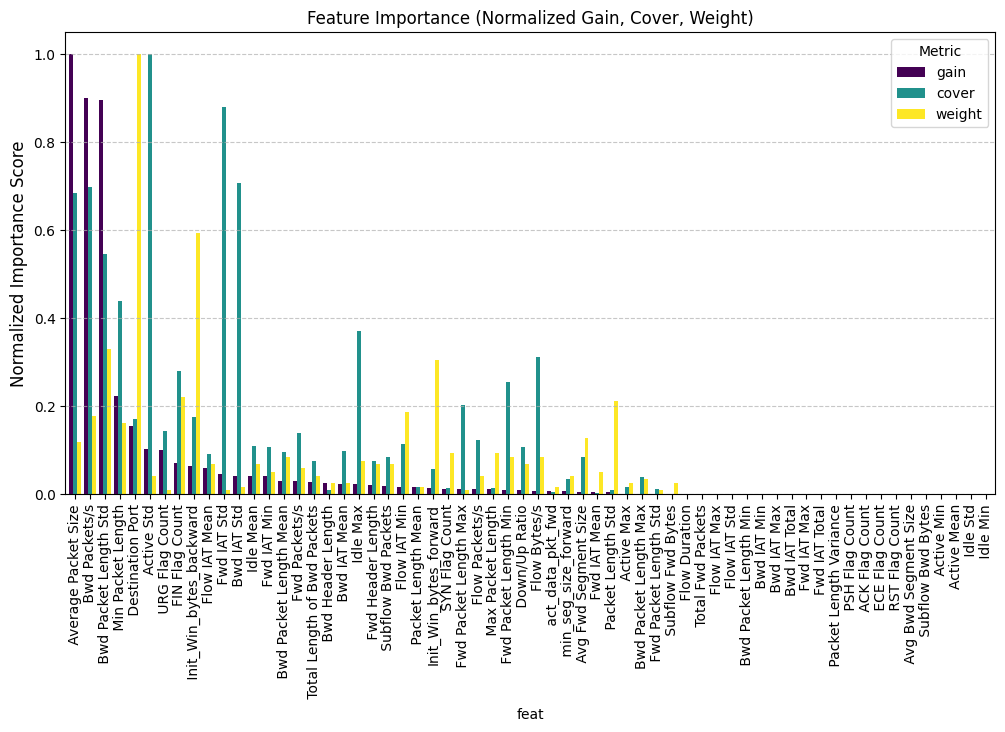

In [27]:
# Plot Feature Importance
importance_df.plot(kind='bar', figsize=(12, 6), width=0.8, colormap='viridis')
#plt.xlabel('Features',fontsize=14)
plt.ylabel('Normalized Importance Score',fontsize=12)
plt.title('Feature Importance (Normalized Gain, Cover, Weight)')
plt.legend(title='Metric')
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

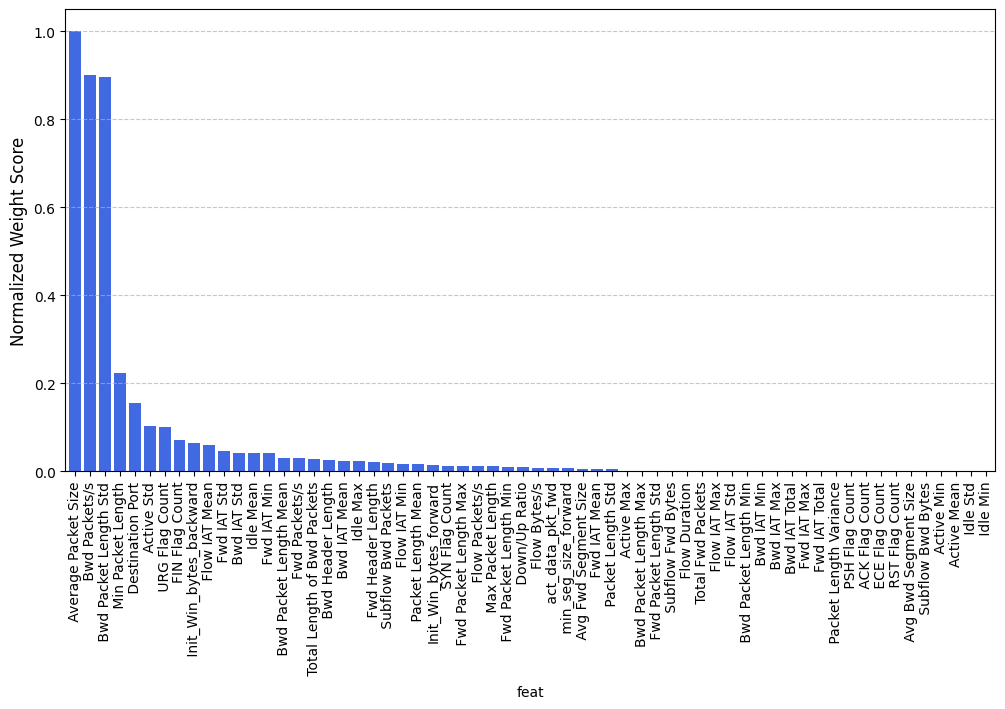

In [28]:
# Plot Gain Scores
plt.figure(figsize=(12, 6))
importance_df['gain'].plot(kind='bar', color='royalblue', width=0.8)

#plt.xlabel('Features', fontsize=14)
plt.ylabel('Normalized Weight Score', fontsize=12)
# plt.title('Feature Importance (Gain Only)', fontsize=14)
plt.xticks(rotation=90)
plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

In [29]:
importance_df

,gain,cover,weight
feat,,,
Average Packet Size,1.000000,0.684721,0.118644
Bwd Packets/s,0.899415,0.697148,0.177966
Bwd Packet Length Std,0.894963,0.547074,0.330508
Min Packet Length,0.222434,0.439331,0.161017
Destination Port,0.154104,0.170840,1.000000
...,...,...,...
Subflow Bwd Bytes,0.000000,0.000000,0.000000
Active Min,0.000000,0.000000,0.000000
Active Mean,0.000000,0.000000,0.000000


In [30]:
y_pred_proba = model.predict_proba(X_valid)
y_pred = (y_pred_proba >= 0.5).astype(int)
y_true = y_valid.values

TP = np.sum((y_pred == 1) & (y_true == 1))
FP = np.sum((y_pred == 1) & (y_true == 0))
FN = np.sum((y_pred == 0) & (y_true == 1))

accuracy  = np.mean(y_pred == y_true)
precision = TP / (TP + FP)
recall    = TP / (TP + FN)

print(f'Accuracy: {accuracy:.4f}')
print(f'Precision: {precision:.4f}')
print(f'Recall: {recall:.4f}')

Accuracy: 0.9973
Precision: 0.9941
Recall: 0.9984


proposed method, compress decision trees

In [31]:
index_list = importance_df.index.tolist()

In [32]:
# Sample the dataset randomly
N = 40000
SampledDataset = cleaned_data_labels.sample(n=N,random_state = 45)

In [33]:
# Define features and target variable
X = SampledDataset.iloc[:, :-1]  # All columns except the last one as features
y = SampledDataset.iloc[:, -1]   # Last column as the target variable

In [34]:
# Import necessary libraries
from sklearn.tree import DecisionTreeClassifier   # Decision Tree model
import joblib                                     # For saving the trained models

num_of_important_features = len(index_list)       # Get the number of important features from the provided index list

In [35]:
# Split the dataset into training and testing sets (80% training, 20% testing)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [36]:
# Initialize lists to store evaluation metrics and results
results = []
precision_list = []
recall_list = []
accuracy_list = []

In [37]:
# Iterate through different numbers of important features
for feature_num in range(1,num_of_important_features):
    # Select a subset of features to include in training and testing
    columns_to_keep = index_list[0:feature_num]
    X_train_subset = X_train.loc[:,columns_to_keep]
    X_test_subset = X_test.loc[:,columns_to_keep]

    # Initialize and train a Decision Tree classifier with a max depth of 4
    model = DecisionTreeClassifier(random_state=42,max_depth=4)
    model.fit(X_train_subset, y_train)
    # # Make predictions on the test set
    y_pred = model.predict(X_test_subset)

    # Calculate evaluation metrics: precision, recall, and accuracy
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)

    # Store computed metrics in respective lists
    precision_list.append(precision)
    recall_list.append(recall)
    accuracy_list.append(accuracy)


   # Store the results for this feature subset
    results.append((feature_num, precision, recall, accuracy))
   # Save the trained model for this feature subset
    joblib.dump(model, f"decision_tree_{feature_num}.joblib")

In [38]:
# Convert results list into a DataFrame for better readability and analysis
results_df = pd.DataFrame(results, columns=['Number of Features', 'Precision', 'Recall', 'Accuracy'])

In [39]:
results_df

,Number of Features,Precision,Recall,Accuracy
0,1,0.816422,0.961326,0.907750
1,2,0.916170,0.954765,0.952000
2,3,0.944951,0.966160,0.967375
3,4,0.943733,0.967196,0.967250
4,5,0.989455,0.939572,0.974500
...,...,...,...,...
56,57,0.984440,0.983080,0.988250
57,58,0.984440,0.983080,0.988250
58,59,0.984440,0.983080,0.988250
59,60,0.984440,0.983080,0.988250


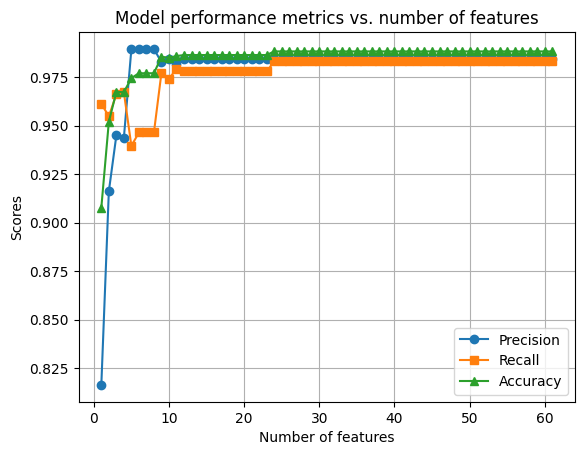

In [40]:
# Performance metric curves
plt.plot(range(1, len(precision_list) + 1), precision_list, marker='o', label='Precision')
plt.plot(range(1, len(recall_list) + 1), recall_list, marker='s', label='Recall')
plt.plot(range(1, len(accuracy_list) + 1), accuracy_list, marker='^', label='Accuracy')

plt.xlabel('Number of features')
plt.ylabel('Scores')
plt.title('Model performance metrics vs. number of features')
plt.legend()
plt.grid(True)
plt.show()

In [41]:
from sklearn.tree import export_graphviz
import graphviz
import joblib

# Select the number of features to visualize the relevent decision tree
feature_num = 8  # Change this value to visualize a model trained with a different number of features

# Load the trained Decision Tree model corresponding to the selected feature subset
model = joblib.load(f"decision_tree_{feature_num}.joblib")

# Get the corresponding feature names
columns_to_keep = index_list[:feature_num]

# Export tree as a DOT format string
dot_data = export_graphviz(model, out_file=None,
                           feature_names=columns_to_keep,
                           class_names=['Class 0', 'Class 1'],
                           filled=True, rounded=True, special_characters=True)

# Render and display the tree
graph = graphviz.Source(dot_data)
graph.render(f"decision_tree_{feature_num}")  # Saves as 'decision_tree_7.pdf' or other formats

'decision_tree_8.pdf'

## GlassBoost with max depth = 5

In [42]:
# Same experiment as the depth-4 loop, but with max_depth = 5
# (uses the X_train / X_test split of the 40,000 sampled rows created above)
results_d5 = []
precision_list_d5 = []
recall_list_d5 = []
accuracy_list_d5 = []

for feature_num in range(1, num_of_important_features):
    columns_to_keep = index_list[0:feature_num]
    X_train_subset = X_train.loc[:, columns_to_keep]
    X_test_subset = X_test.loc[:, columns_to_keep]

    # Decision Tree with a max depth of 5
    model_d5 = DecisionTreeClassifier(random_state=42, max_depth=5)
    model_d5.fit(X_train_subset, y_train)
    y_pred = model_d5.predict(X_test_subset)

    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    accuracy = accuracy_score(y_test, y_pred)

    precision_list_d5.append(precision)
    recall_list_d5.append(recall)
    accuracy_list_d5.append(accuracy)
    results_d5.append((feature_num, precision, recall, accuracy))

    # separate file name so the depth-4 models are not overwritten
    joblib.dump(model_d5, f"decision_tree_depth5_{feature_num}.joblib")

results_df_d5 = pd.DataFrame(results_d5, columns=['Number of Features', 'Precision', 'Recall', 'Accuracy'])

In [43]:
results_df_d5

,Number of Features,Precision,Recall,Accuracy
0,1,0.820490,0.959599,0.909375
1,2,0.928405,0.962707,0.959625
2,3,0.949796,0.966851,0.969500
3,4,0.950441,0.966851,0.969750
4,5,0.991513,0.968232,0.985500
...,...,...,...,...
56,57,0.986197,0.986878,0.990250
57,58,0.986197,0.986878,0.990250
58,59,0.986197,0.986878,0.990250
59,60,0.986197,0.986878,0.990250


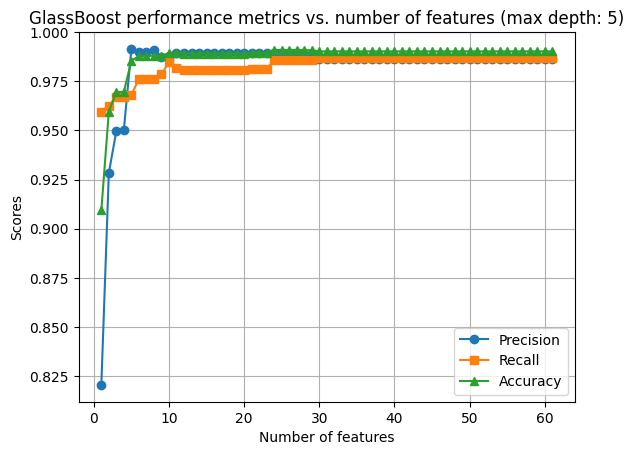

In [44]:
# Performance metric curves (max depth = 5)
plt.plot(range(1, len(precision_list_d5) + 1), precision_list_d5, marker='o', label='Precision')
plt.plot(range(1, len(recall_list_d5) + 1), recall_list_d5, marker='s', label='Recall')
plt.plot(range(1, len(accuracy_list_d5) + 1), accuracy_list_d5, marker='^', label='Accuracy')

plt.xlabel('Number of features')
plt.ylabel('Scores')
plt.title('GlassBoost performance metrics vs. number of features (max depth: 5)')
plt.legend()
plt.grid(True)
plt.show()

### GlassBoost decision tree graph (max depth = 5, top 8 features)

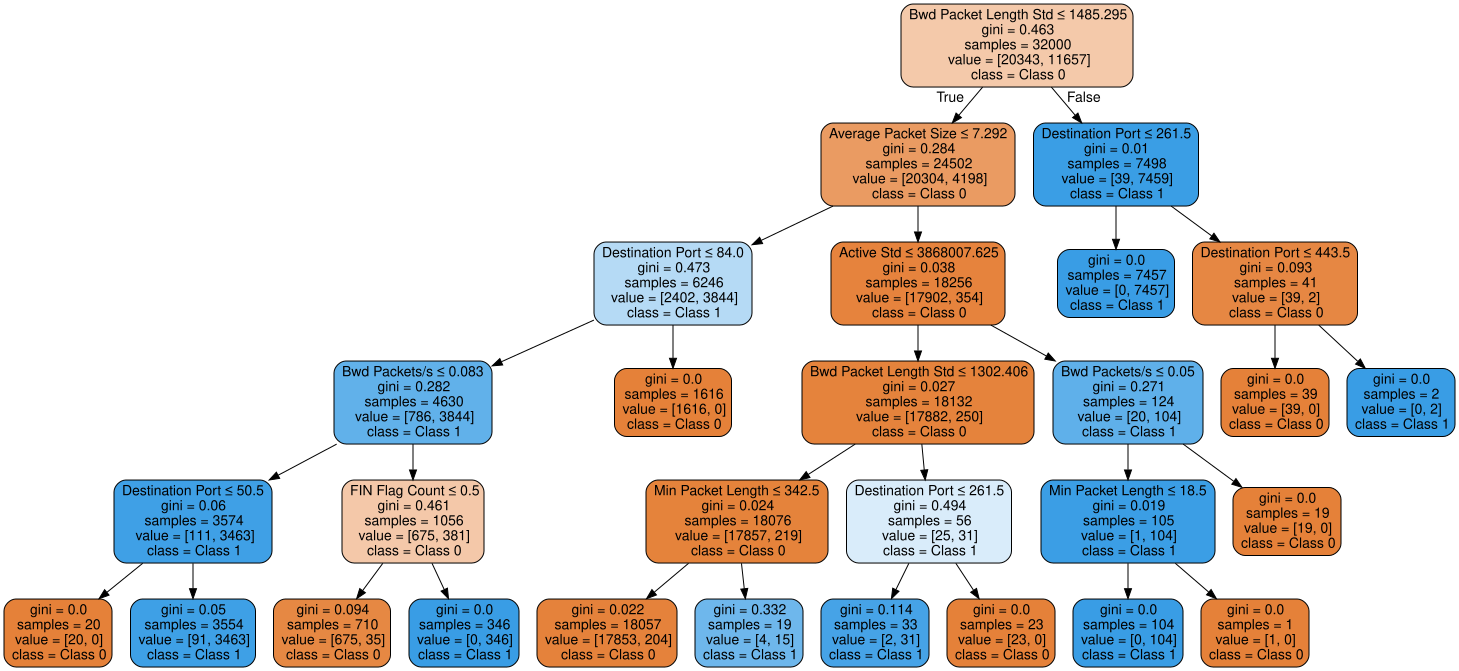

In [45]:
from sklearn.tree import export_graphviz
import graphviz
import joblib

feature_num = 8   # number of top-gain features (the paper uses 8 for Figure 9)

# Load the depth-5 tree trained on the top `feature_num` features
model_d5 = joblib.load(f"decision_tree_depth5_{feature_num}.joblib")
columns_to_keep = index_list[:feature_num]

dot_data = export_graphviz(model_d5, out_file=None,
                           feature_names=columns_to_keep,
                           class_names=['Class 0', 'Class 1'],
                           filled=True, rounded=True, special_characters=True)

graph_d5 = graphviz.Source(dot_data)
graph_d5.render(f"decision_tree_depth5_{feature_num}", format="png", cleanup=True)  # saves the PNG
graph_d5   # displays the tree in the notebook

In [46]:
print("Leaf nodes (= number of IF-THEN rules):", model_d5.get_n_leaves())

Leaf nodes (= number of IF-THEN rules): 15


## SHAP comparison

In [47]:
!pip install shap
import shap

In [48]:
# Retrain your SCRATCH XGBoost under its own name. (The variable `model` was overwritten by the
# decision-tree loops, and training is deterministic, so this gives the same model and gain ranking.)
X_all = cleaned_data_labels.iloc[:, :-1]
y_all = cleaned_data_labels.iloc[:, -1]
X_tr_full, X_val_full, y_tr_full, y_val_full = train_test_split(X_all, y_all, test_size=0.3, random_state=42)

scratch_xgb = SimpleXGBoost(max_depth=4, eta=0.1)
scratch_xgb.fit(X_tr_full, y_tr_full, X_val_full, y_val_full, num_rounds=50, early_stopping_rounds=10)

# sanity check: the gain ranking matches the index_list used for GlassBoost
gain_rank = scratch_xgb.importance()['gain'].sort_values(ascending=False).index.tolist()
print("Same top-8 gain features as index_list:", gain_rank[:8] == index_list[:8])

[0] train-logloss:0.56634 eval-logloss:0.56649
[1] train-logloss:0.49530 eval-logloss:0.49546
[2] train-logloss:0.43711 eval-logloss:0.43727
[3] train-logloss:0.38852 eval-logloss:0.38869
[4] train-logloss:0.34740 eval-logloss:0.34758
[5] train-logloss:0.30961 eval-logloss:0.30979
[6] train-logloss:0.27711 eval-logloss:0.27729
[7] train-logloss:0.24897 eval-logloss:0.24914
[8] train-logloss:0.22444 eval-logloss:0.22460
[9] train-logloss:0.20297 eval-logloss:0.20314
[10] train-logloss:0.18411 eval-logloss:0.18428
[11] train-logloss:0.16748 eval-logloss:0.16762
[12] train-logloss:0.15278 eval-logloss:0.15292
[13] train-logloss:0.13955 eval-logloss:0.13968
[14] train-logloss:0.12800 eval-logloss:0.12811
[15] train-logloss:0.11758 eval-logloss:0.11775
[16] train-logloss:0.10829 eval-logloss:0.10845
[17] train-logloss:0.09984 eval-logloss:0.10002
[18] train-logloss:0.09242 eval-logloss:0.09265
[19] train-logloss:0.08568 eval-logloss:0.08593
[20] train-logloss:0.07971 eval-logloss:0.07998
[2

In [49]:
def scratch_to_shap_dict(scratch_model, X_background):
    """Convert SimpleXGBoost trees to the dict format shap.TreeExplainer accepts."""
    Xv = X_background.values.astype(float)
    rows = np.arange(len(Xv))
    trees = []
    for t in scratch_model.trees:
        n = len(t.feature)
        # number of background samples reaching every node (SHAP's node_sample_weight)
        cover = np.zeros(n)
        cover[0] = len(Xv)
        node = np.zeros(len(Xv), dtype=int)
        for _ in range(t.max_depth):
            f = t.feature[node]
            internal = f >= 0
            go_left = Xv[rows, np.where(internal, f, 0)] <= t.thr[node]
            nxt = np.where(internal, np.where(go_left, t.left[node], t.right[node]), node)
            np.add.at(cover, nxt[internal], 1)
            node = nxt
        trees.append({
            "children_left":  t.left.astype(np.int32),
            "children_right": t.right.astype(np.int32),
            "children_default": t.left.astype(np.int32),          # no NaNs after cleaning
            "features":   np.where(t.feature >= 0, t.feature, -2).astype(np.int32),
            "thresholds": t.thr.astype(np.float64),
            "values":     t.value.reshape(-1, 1).astype(np.float64),   # leaf weights already include eta
            "node_sample_weight": cover,
        })
    return {"trees": trees, "base_offset": float(scratch_model.base),
            "tree_output": "log_odds", "objective": "binary_crossentropy",
            "input_dtype": np.float64, "internal_dtype": np.float64}

max |SHAP reconstruction - model output|: 3.4638958368304884e-14


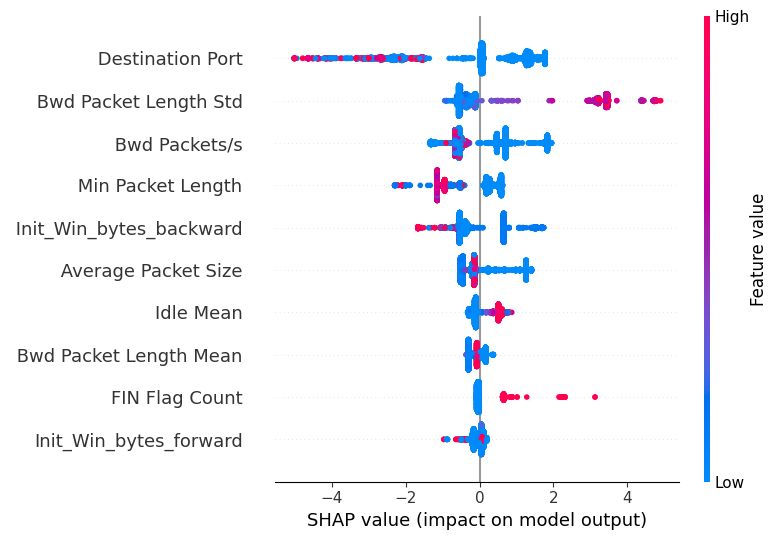

In [50]:
# SHAP on the scratch XGBoost (same model that produced the gain scores)
shap_model = scratch_to_shap_dict(scratch_xgb, X_tr_full)
explainer = shap.TreeExplainer(shap_model)

X_shap = X_val_full.sample(n=5000, random_state=42)
shap_values = explainer.shap_values(X_shap.values)

# additivity check: base value + sum of SHAP values must equal the model's raw log-odds output
margin = np.log(scratch_xgb.predict_proba(X_shap) / (1 - scratch_xgb.predict_proba(X_shap)))
recon = explainer.expected_value + shap_values.sum(axis=1)
print("max |SHAP reconstruction - model output|:", np.abs(recon - margin).max())   # should be ~0

# SHAP summary plot (top 10 features), like Figure 11 of the paper
shap.summary_plot(shap_values, X_shap, max_display=10)

In [51]:
# Rank features by global SHAP importance = mean(|SHAP value|)
shap_importance = pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns).sort_values(ascending=False)
shap_index_list = shap_importance.index.tolist()

print("Overlap of top-8 features (gain vs SHAP):", len(set(index_list[:8]) & set(shap_index_list[:8])), "/ 8")
shap_importance.head(10)

Overlap of top-8 features (gain vs SHAP): 5 / 8


,0
Destination Port,1.297180
Bwd Packet Length Std,1.134709
Bwd Packets/s,0.767163
Min Packet Length,0.645920
Init_Win_bytes_backward,0.595508
Average Packet Size,0.411318
Idle Mean,0.238154
Bwd Packet Length Mean,0.163432
FIN Flag Count,0.120519
Init_Win_bytes_forward,0.105173


In [52]:
# SHAP trees: decision trees (max depth 4) trained on the top-d SHAP features of the scratch XGBoost,
# using the same 40,000-sample train/test split as GlassBoost
shap_results = []

for feature_num in range(1, num_of_important_features):
    columns_to_keep = shap_index_list[0:feature_num]
    X_train_subset = X_train.loc[:, columns_to_keep]
    X_test_subset = X_test.loc[:, columns_to_keep]

    shap_tree = DecisionTreeClassifier(random_state=42, max_depth=4)
    shap_tree.fit(X_train_subset, y_train)
    y_pred = shap_tree.predict(X_test_subset)

    shap_results.append((feature_num,
                         precision_score(y_test, y_pred),
                         recall_score(y_test, y_pred),
                         accuracy_score(y_test, y_pred)))

shap_results_df = pd.DataFrame(shap_results, columns=['Number of Features', 'Precision', 'Recall', 'Accuracy'])
shap_results_df

,Number of Features,Precision,Recall,Accuracy
0,1,0.841860,1.000000,0.93200
1,2,0.902952,0.992749,0.95875
2,3,0.958217,0.950276,0.96700
3,4,0.991336,0.948204,0.97825
4,5,0.990048,0.996202,0.99500
...,...,...,...,...
56,57,0.984440,0.983080,0.98825
57,58,0.984440,0.983080,0.98825
58,59,0.984440,0.983080,0.98825
59,60,0.984440,0.983080,0.98825


### GlassBoost vs SHAP (side by side)

In [53]:
# Comparison table (first 9 features, as in Table 5 of the paper)
comparison_df = pd.DataFrame({
    'Number of Features': results_df['Number of Features'],
    'GlassBoost (depth 4) Acc': results_df['Accuracy'],
    'GlassBoost (depth 5) Acc': results_df_d5['Accuracy'],
    'SHAP tree (depth 4) Acc': shap_results_df['Accuracy'],
}).head(9)
comparison_df.round(4)

,Number of Features,GlassBoost (depth 4) Acc,GlassBoost (depth 5) Acc,SHAP tree (depth 4) Acc
0,1,0.9078,0.9094,0.9320
1,2,0.9520,0.9596,0.9588
2,3,0.9674,0.9695,0.9670
3,4,0.9672,0.9698,0.9782
4,5,0.9745,0.9855,0.9950
5,6,0.9770,0.9879,0.9830
6,7,0.9770,0.9879,0.9848
7,8,0.9770,0.9881,0.9848
8,9,0.9855,0.9878,0.9848


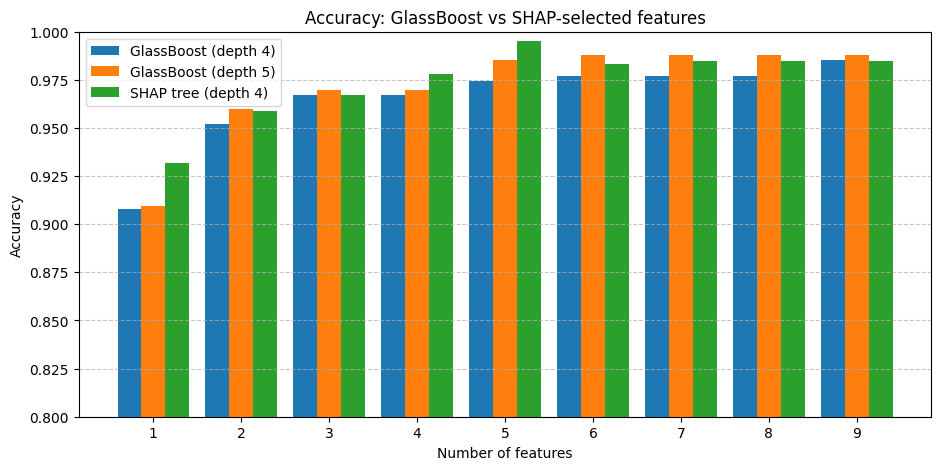

In [54]:
# Grouped bar chart: accuracy of GlassBoost vs SHAP for 1-9 features
n_show = 9
x = np.arange(1, n_show + 1)
w = 0.27

plt.figure(figsize=(11, 5))
plt.bar(x - w, results_df['Accuracy'][:n_show],    width=w, label='GlassBoost (depth 4)')
plt.bar(x,     results_df_d5['Accuracy'][:n_show], width=w, label='GlassBoost (depth 5)')
plt.bar(x + w, shap_results_df['Accuracy'][:n_show], width=w, label='SHAP tree (depth 4)')

plt.xticks(x)
plt.ylim(0.8, 1.0)
plt.xlabel('Number of features')
plt.ylabel('Accuracy')
plt.title('Accuracy: GlassBoost vs SHAP-selected features')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

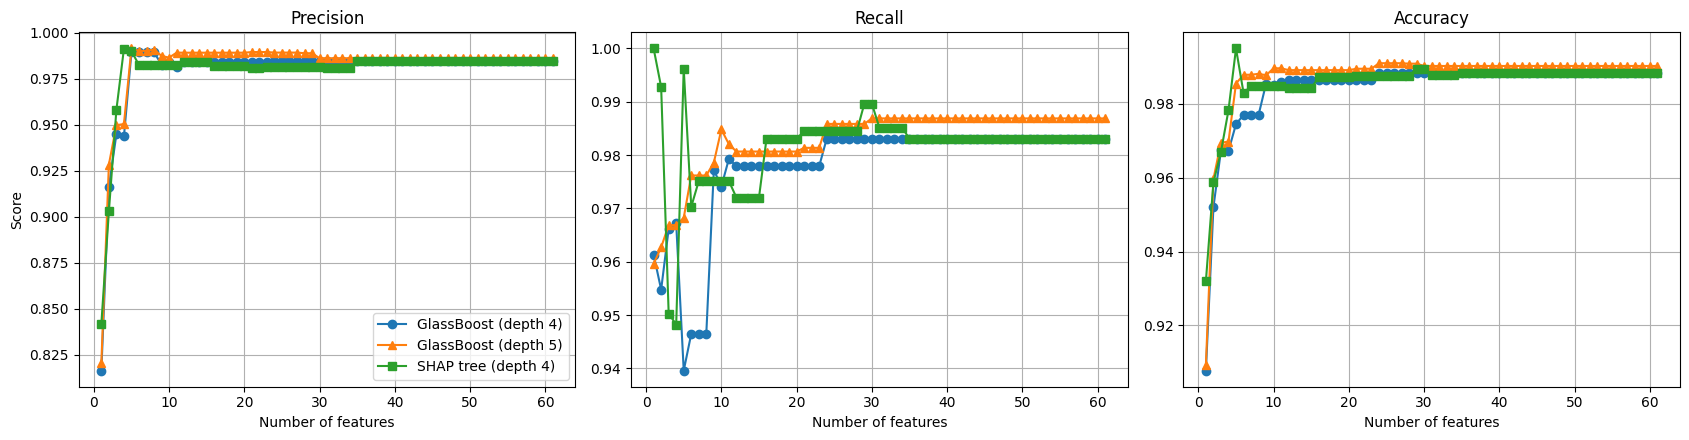

In [55]:
# Precision / Recall / Accuracy curves: GlassBoost (depth 4) vs SHAP tree (depth 4)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5), sharex=True)

for ax, metric in zip(axes, ['Precision', 'Recall', 'Accuracy']):
    ax.plot(results_df['Number of Features'], results_df[metric], marker='o', label='GlassBoost (depth 4)')
    ax.plot(results_df_d5['Number of Features'], results_df_d5[metric], marker='^', label='GlassBoost (depth 5)')
    ax.plot(shap_results_df['Number of Features'], shap_results_df[metric], marker='s', label='SHAP tree (depth 4)')
    ax.set_title(metric)
    ax.set_xlabel('Number of features')
    ax.grid(True)
axes[0].set_ylabel('Score')
axes[0].legend()
plt.tight_layout()
plt.show()